## Лабораторная работа № 8

## Бинарная классификация с использованием нейросети

Цель работы: изучить архитектуру и принцип работы нейронных сетей на примере решения задачи бинарной классификации.

Основные задачи:

- освоение работы с многослойным перцептроном;
- оценка эффективности модели на практическом примере;
- изучение методов визуализации модели и оценки ее корректности.

Используем **cancer_data.csv**, вариант 4 — прогнозирование рака. Целевая переменная **Diagnosis**: 0 — отсутствие рака, 1 — наличие рака.

## 1. Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Фиксируем случайность разбиения и нейросети
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

## 2. Загрузка и первичный анализ данных

Используем датасет из 4 лабораторной работы.

In [2]:
# Загружаем набор данных
data_path = "cancer_data.csv"
df = pd.read_csv(data_path)
print("Размерность исходного набора данных:", df.shape)
display(df.head())

Размерность исходного набора данных: (1500, 9)


,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory,Diagnosis
0,58,1,16.085313,0,1,8.146251,4.148219,1,1
1,71,0,30.828784,0,1,9.361630,3.519683,0,0
2,48,1,38.785084,0,2,5.135179,4.728368,0,1
3,34,0,30.040296,0,0,9.502792,2.044636,0,0
4,62,1,35.479721,0,0,5.356890,3.309849,0,1


In [3]:
# Типы данных, количество заполненных значений и описательная статистика
df.info()
display(df.describe())

print("\nПропуски по столбцам:")
print(df.isna().sum())
print("\nКоличество дубликатов:", df.duplicated().sum())
print("\nРаспределение Diagnosis:")
print(df["Diagnosis"].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1500 non-null   int64  
 1   Gender            1500 non-null   int64  
 2   BMI               1500 non-null   float64
 3   Smoking           1500 non-null   int64  
 4   GeneticRisk       1500 non-null   int64  
 5   PhysicalActivity  1500 non-null   float64
 6   AlcoholIntake     1500 non-null   float64
 7   CancerHistory     1500 non-null   int64  
 8   Diagnosis         1500 non-null   int64  
dtypes: float64(3), int64(6)
memory usage: 105.6 KB


,Age,Gender,BMI,Smoking,GeneticRisk,PhysicalActivity,AlcoholIntake,CancerHistory,Diagnosis
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,50.320000,0.490667,27.513321,0.269333,0.508667,4.897929,2.417987,0.144000,0.371333
std,17.640968,0.500080,7.230012,0.443761,0.678895,2.866162,1.419318,0.351207,0.483322
min,20.000000,0.000000,15.000291,0.000000,0.000000,0.002410,0.001215,0.000000,0.000000
25%,35.000000,0.000000,21.483134,0.000000,0.000000,2.434609,1.210598,0.000000,0.000000
50%,51.000000,0.000000,27.598494,0.000000,0.000000,4.834316,2.382971,0.000000,0.000000
75%,66.000000,1.000000,33.850837,1.000000,1.000000,7.409896,3.585624,0.000000,1.000000
max,80.000000,1.000000,39.958688,1.000000,2.000000,9.994607,4.987115,1.000000,1.000000



Пропуски по столбцам:
Age                 0
Gender              0
BMI                 0
Smoking             0
GeneticRisk         0
PhysicalActivity    0
AlcoholIntake       0
CancerHistory       0
Diagnosis           0
dtype: int64

Количество дубликатов: 0

Распределение Diagnosis:
Diagnosis
0    943
1    557
Name: count, dtype: int64


### Вывод по первичному анализу

Набор содержит 1500 строк и 9 столбцов: 8 исходных признаков и Diagnosis. Пропусков и полностью совпадающих строк нет. Класс 0 содержит 943 записи, класс 1 — 557; при разбиении используем стратификацию, чтобы сохранить соотношение классов.

## 3. Извлечение последней строки датафрейма (практическое применение)

In [4]:
# Сохраняем последнюю строку для отдельной проверки
row_to_remove = df.iloc[-1].copy()
df = df.drop(index=row_to_remove.name).copy()

print("Отложенная строка (Series):")
print(row_to_remove)
print(f"Тип: {type(row_to_remove)}")
print("Размерность данных после исключения строки:", df.shape)

Отложенная строка (Series):
Age                 67.000000
Gender               1.000000
BMI                 23.663104
Smoking              0.000000
GeneticRisk          0.000000
PhysicalActivity     2.525860
AlcoholIntake        2.856600
CancerHistory        1.000000
Diagnosis            0.000000
Name: 1499, dtype: float64
Тип: <class 'pandas.core.series.Series'>
Размерность данных после исключения строки: (1499, 9)


Эта строка не участвует в обучении, валидации и тестировании. В конце сравним отдельный прогноз с ее известным Diagnosis.

## 4. Предобработка данных

Выбираем признаки и целевую переменную. Все обучаемые преобразования будем настраивать только на тренировочных данных.

In [5]:
# Исходные признаки и целевая переменная
features = ["Age", "Gender", "BMI", "Smoking", "GeneticRisk", "PhysicalActivity", "AlcoholIntake", "CancerHistory"]
X = df[features].copy()
y = df["Diagnosis"].copy()

# При отсутствии метки объект нельзя использовать для обучения
labeled = y.notna()
X = X.loc[labeled]
y = y.loc[labeled].astype(int)

print("Размерность исходных признаков:", X.shape)
print("Уникальные классы:", sorted(y.unique()))
print("\nПропуски в признаках:")
print(X.isna().sum())

Размерность исходных признаков: (1499, 8)
Уникальные классы: [np.int64(0), np.int64(1)]

Пропуски в признаках:
Age                 0
Gender              0
BMI                 0
Smoking             0
GeneticRisk         0
PhysicalActivity    0
AlcoholIntake       0
CancerHistory       0
dtype: int64


In [6]:
# Сначала отделяем тестовую выборку (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Затем выделяем validation из оставшихся данных
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("Обучающая выборка:", X_train.shape)
print("Валидационная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)
print("\nРаспределение классов по выборкам:")
display(pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index()
}))

Обучающая выборка: (959, 8)
Валидационная выборка: (240, 8)
Тестовая выборка: (300, 8)

Распределение классов по выборкам:


,Train,Validation,Test
Diagnosis,,,
0,602,151,189
1,357,89,111


Пояснения:

- После исключения последней строки остается 1499 объектов: 959 для обучения, 240 для валидации и 300 для тестирования.
- `stratify` сохраняет соотношение классов при разбиении.
- Валидация выделена до обучения предобработки, поэтому ее значения не участвуют в вычислении статистик нормализатора.
- Пропусков сейчас нет. Ниже задаем SimpleImputer, который обработает NaN, если они появятся в признаках.

## 5. Кодирование и масштабирование признаков

Используем методы sklearn: **OneHotEncoder** для Gender и GeneticRisk и **StandardScaler** для масштабирования. Smoking и CancerHistory уже закодированы как 0/1. OneHotEncoder сохраняет выбранную схему кодирования для всех выборок и нового пациента.

При кодировании одну категорию отбрасываем. Это дает один столбец Gender и два столбца GeneticRisk. После кодирования у модели 9 входных признаков.

In [7]:
# Числовые признаки, включая признаки с готовой бинарной кодировкой
numeric_features = ["Age", "BMI", "Smoking", "PhysicalActivity", "AlcoholIntake", "CancerHistory"]
categorical_features = ["Gender", "GeneticRisk"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(categories=[[0, 1], [0, 1, 2]],
                              drop="first", sparse_output=False)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
], verbose_feature_names_out=False)

# Обучаем преобразователи только на train
X_train_scaled = preprocessor.fit_transform(X_train)
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Число признаков после кодирования:", X_train_scaled.shape[1])
print("Названия признаков:", feature_names.tolist())
display(pd.DataFrame(X_train_scaled, columns=feature_names, index=X_train.index).head())

Число признаков после кодирования: 9
Названия признаков: ['Age', 'BMI', 'Smoking', 'PhysicalActivity', 'AlcoholIntake', 'CancerHistory', 'Gender_1', 'GeneticRisk_1', 'GeneticRisk_2']


,Age,BMI,Smoking,PhysicalActivity,AlcoholIntake,CancerHistory,Gender_1,GeneticRisk_1,GeneticRisk_2
491,0.126438,-0.888266,-0.605059,0.451999,1.728671,-0.406508,-1.005227,-0.635688,3.051529
867,1.034709,1.568421,-0.605059,-1.075349,-1.600683,2.459974,0.994800,-0.635688,-0.327705
541,1.318544,-0.442258,-0.605059,1.097601,1.409082,-0.406508,0.994800,-0.635688,-0.327705
944,-1.008901,0.871712,1.652730,-0.839003,-0.086622,-0.406508,-1.005227,-0.635688,-0.327705
765,0.012904,0.666579,-0.605059,1.115296,0.404456,-0.406508,0.994800,-0.635688,3.051529


StandardScaler приводит каждый признак обучающей выборки к нулевому среднему и единичному стандартному отклонению, если его разброс ненулевой. Для validation, test и отдельного пациента применяются те же обученные преобразователи через transform. Целевой столбец Diagnosis в предобработку признаков не входит.

## 6. Построение модели с Keras API

Создадим полносвязную нейронную сеть.

In [8]:
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,753 (10.75 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

Пояснения к архитектуре:

1. **Input** задает 9 входных признаков после кодирования.
2. Первый **Dense** содержит 64 нейрона с ReLU.
3. **Dropout(0.3)** во время обучения случайно отключает 30% выходов предыдущего слоя.
4. Второй **Dense** содержит 32 нейрона с ReLU.
5. **Dropout(0.2)** дополнительно снижает риск переобучения.
6. Выходной **Dense(1)** с Sigmoid выдает значение от 0 до 1 для класса Diagnosis=1.

Sequential передает данные последовательно через эти слои. Во время оценки и прогнозирования Dropout отключен.

## 7. Компиляция модели

In [9]:
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 100

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]
)

Параметры компиляции:

- **Adam** обновляет веса; learning rate равен 0.001.
- **Binary Crossentropy** используется для бинарной классификации.
- **Accuracy, Precision и Recall** отслеживают качество прогнозов.
- Batch size равен 32, максимальное количество эпох — 100. Фактическую продолжительность обучения определяет ранняя остановка.

## 8. Обучение модели с валидацией

Используем отдельную валидационную выборку для контроля val_loss и восстановления лучших весов.

In [10]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    callbacks=[early_stop]
)

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print("Количество выполненных эпох:", len(history.history["loss"]))
print("Эпоха с минимальным val_loss:", best_epoch)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.5996 - loss: 0.6559 - precision: 0.4569 - recall: 0.4006 - val_accuracy: 0.7250 - val_loss: 0.5830 - val_precision: 0.8485 - val_recall: 0.3146
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7112 - loss: 0.5630 - precision: 0.7381 - recall: 0.3473 - val_accuracy: 0.7750 - val_loss: 0.4959 - val_precision: 0.8889 - val_recall: 0.4494
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7925 - loss: 0.4786 - precision: 0.8559 - recall: 0.5322 - val_accuracy: 0.8667 - val_loss: 0.4164 - val_precision: 0.8904 - val_recall: 0.7303
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8373 - loss: 0.4177 - precision: 0.8361 - recall: 0.7003 - val_accuracy: 0.8792 - val_loss: 0.3590 - val_precision: 0.9054 - val_recall: 0.7528
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8373 - loss: 0.3696 - precision: 0.8131 - recall: 0.7311 - val_accuracy: 0.8708 - val_loss: 0.3294

Что делает EarlyStopping:

- Отслеживает потери на validation после каждой эпохи.
- Останавливает обучение после 10 эпох без улучшения val_loss.
- `restore_best_weights=True` восстанавливает веса с минимальными валидационными потерями.

Веса не обучаются на validation; тест не используется для ранней остановки или выбора параметров.

## 9. Оценка модели на тестовых данных

In [11]:
# Оцениваем выбранные по validation веса на независимом тесте
test_metrics = model.evaluate(X_test_scaled, y_test, verbose=0, return_dict=True)
y_prob = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

# Precision, Recall и F1 относятся к положительному классу «Есть рак»
test_acc = accuracy_score(y_test, y_pred)
test_prec = precision_score(y_test, y_pred, zero_division=0)
test_rec = recall_score(y_test, y_pred, zero_division=0)
test_f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Test Loss: {test_metrics['loss']:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_prec:.4f}")
print(f"Test Recall: {test_rec:.4f}")
print(f"Test F1: {test_f1:.4f}")

Test Loss: 0.3413
Test Accuracy: 0.8633
Test Precision: 0.8431
Test Recall: 0.7748
Test F1: 0.8075


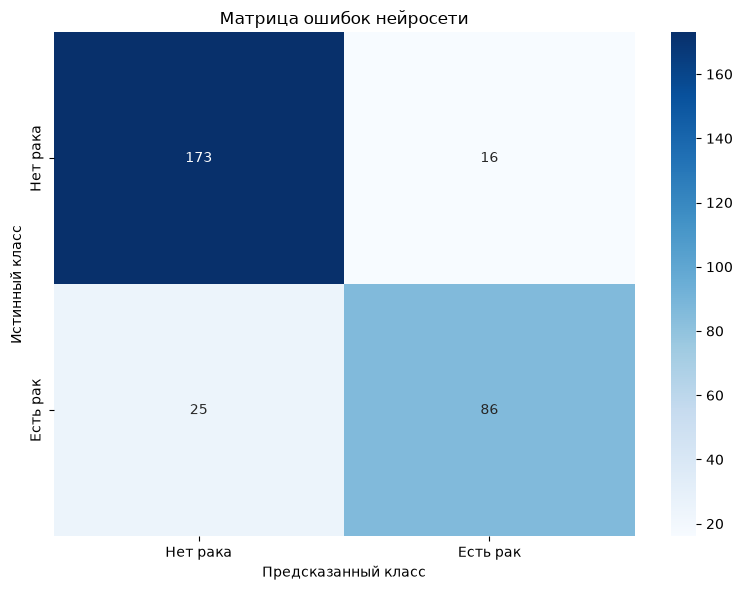

In [12]:
# Матрица ошибок помогает интерпретировать метрики по классам
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Нет рака", "Есть рак"],
            yticklabels=["Нет рака", "Есть рак"])
plt.title("Матрица ошибок нейросети")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.tight_layout()
plt.show()

### Вывод по оценке модели

На тестовой выборке accuracy составляет **86.33%**, precision положительного класса — **84.31%**, recall — **77.48%**, F1 — **80.75%**.

Модель правильно выявила 86 из 111 объектов с Diagnosis=1. Допущено 25 ложноотрицательных и 16 ложноположительных прогнозов. Таким образом, общая доля правильных ответов не описывает все ошибки: для задачи обнаружения класса 1 необходимо учитывать полноту вместе с precision и F1.

## 10. Визуализация процесса обучения

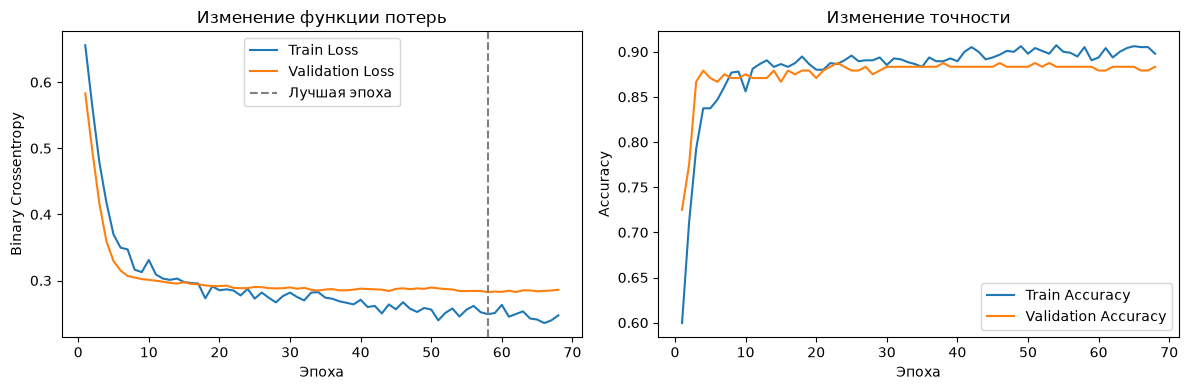

In [13]:
epochs_completed = np.arange(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_completed, history.history["loss"], label="Train Loss")
plt.plot(epochs_completed, history.history["val_loss"], label="Validation Loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label="Лучшая эпоха")
plt.xlabel("Эпоха")
plt.ylabel("Binary Crossentropy")
plt.title("Изменение функции потерь")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_completed, history.history["accuracy"], label="Train Accuracy")
plt.plot(epochs_completed, history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Изменение точности")
plt.legend()
plt.tight_layout()
plt.show()

### Вывод по графикам обучения

Ранняя остановка завершила обучение после 68 эпох. Минимальный val_loss достигнут на **58-й эпохе** и равен **0.2824**. Валидационная accuracy на этой эпохе составляет 88.33%.

На выбранной эпохе валидационные потери выше тренировочных; на данных, не использованных для обновления весов, качество отличается от тренировочного. Ранняя остановка ограничивает продолжение обучения после прекращения улучшения val_loss. Веса выбраны по минимальному val_loss и восстановлены перед оценкой на тесте. Тренировочная кривая получена с активным Dropout, валидационная — без него, поэтому их значения не обязаны совпадать.

## 11. Предсказание для нового пациента

Используем отложенную в начале строку. Передаем исходные признаки в тот же обученный preprocessor, чтобы не задавать dummy-столбцы вручную.

In [14]:
new_patient = row_to_remove[features].to_frame().T
new_scaled = preprocessor.transform(new_patient)
prob = float(model.predict(new_scaled, verbose=0).ravel()[0])
predicted_diagnosis = int(prob > 0.5)
true_diagnosis = int(row_to_remove["Diagnosis"])

print(f"Оценка вероятности класса Diagnosis=1: {prob:.4f}")
print("Предсказанный Diagnosis:", predicted_diagnosis)
print("Известный Diagnosis:", true_diagnosis)
print("Прогноз совпал с известной меткой:", predicted_diagnosis == true_diagnosis)

Оценка вероятности класса Diagnosis=1: 0.9983
Предсказанный Diagnosis: 1
Известный Diagnosis: 0
Прогноз совпал с известной меткой: False


### Вывод по отдельному прогнозу

Оценка принадлежности к классу Diagnosis=1 для отложенной строки составляет 0.9983; при пороге 0.5 предсказан класс 1. Получен ложноположительный прогноз: модель предсказала Diagnosis=1, хотя известная метка равна 0. Это отдельная ошибка модели, которую необходимо учитывать вместе с тестовыми метриками. Для нового объекта использованы те же кодировщик и нормализаторы, что и для обучающих данных.

## 12. Итоговые пояснения и заключение

В ходе работы построена нейронная сеть для бинарной классификации по признакам набора cancer_data.csv. Категориальные признаки закодированы с помощью OneHotEncoder, а признаки масштабированы с помощью StandardScaler. Преобразователи обучены только на тренировочной выборке и применены к валидационной, тестовой выборкам и отдельному пациенту.

Модель содержит два скрытых слоя с 64 и 32 нейронами и активацией ReLU. Dropout используется для снижения риска переобучения. Выходной слой с Sigmoid оценивает вероятность класса Diagnosis=1. Для обучения использованы оптимизатор Adam и функция потерь Binary Crossentropy. Обучение завершилось после 68 эпох; EarlyStopping восстановил веса 58-й эпохи с минимальным val_loss.

На тестовой выборке получены accuracy **86.33%**, precision **84.31%**, recall **77.48%** и F1 **80.75%**. Модель допустила 25 ложноотрицательных и 16 ложноположительных прогнозов. Прогноз для отдельно отложенной строки также оказался ложноположительным.

Нейросеть позволяет решать задачу классификации на данном наборе данных, но допускает ошибки. Для оценки качества необходимо учитывать не только accuracy, но и precision, recall, F1 и матрицу ошибок.